# BTTH2 (Lab02): Classification — Phân loại cảnh báo ngày vượt ngưỡng bụi mịn PM2.5 tại TP.HCM

Code lấy nguyên cấu trúc từ bài **BTTH2 — Python cho Máy học** (`BTTH2.ipynb`: phân loại với `KNeighborsClassifier`, `DecisionTreeClassifier`, `RandomForestClassifier`, tối ưu siêu tham số bằng `GridSearchCV`, đánh giá bằng `ConfusionMatrixDisplay`, `RocCurveDisplay`, `Precision`, `Recall`, `F1-score`), **chỉ đổi dữ liệu đầu vào** sang bài toán phân loại ngày vượt ngưỡng bụi mịn PM2.5 (> 25 µg/m³, mức bắt đầu chuyển từ *Tốt* sang *Trung bình/Kém* theo QĐ 1459/QĐ-TCMT).

| Bài Lab gốc (`BTTH2.ipynb`) | Bản áp dụng cho AirHCM (`Lab02_PM25_HCM.ipynb`) |
|---|---|
| Đặc trưng đầu vào `X` | 6 biến khí tượng trong ngày (`temperature_2m`, `relative_humidity_2m`, `wind_speed_10m`, `precipitation`, `surface_pressure`, `mua`) + nồng độ `pm2_5_hom_qua` |
| Nhãn phân loại `y` | `0`: An toàn / Tốt (PM2.5 ≤ 25 µg/m³) · `1`: Cảnh báo vượt ngưỡng Tốt (PM2.5 > 25 µg/m³) |
| Mô hình | `KNeighborsClassifier`, `DecisionTreeClassifier` + `GridSearchCV`, `RandomForestClassifier` + `GridSearchCV` |
| Đánh giá | `ConfusionMatrixDisplay`, `RocCurveDisplay`, `Accuracy`, `Precision`, `Recall`, `F1-score` |

In [1]:
# ===== BƯỚC CHUẨN BỊ DỮ LIỆU ĐẦU VÀO =====
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

goc = Path.cwd()
while not (goc / 'du_lieu' / 'gio_cache.csv').exists() and goc.parent != goc:
    goc = goc.parent
gio = pd.read_csv(goc / 'du_lieu' / 'gio_cache.csv', parse_dates=['time'])

ngay = gio.set_index('time').resample('D').agg({
    'pm2_5': 'mean', 'pm10': 'mean',
    'temperature_2m': 'mean', 'relative_humidity_2m': 'mean', 'wind_speed_10m': 'mean',
    'precipitation': 'sum', 'surface_pressure': 'mean',
}).interpolate(limit=3).dropna()

ngay['mua'] = LabelEncoder().fit_transform(np.where(ngay.index.month.isin(range(5, 12)), 'Y', 'N'))
ngay['pm2_5_hom_qua'] = ngay['pm2_5'].shift(1)
ngay = ngay.dropna()

# Nhãn phân loại: 1 nếu PM2.5 trung bình ngày > 25 µg/m³ (vượt mức Tốt theo VN_AQI), 0 nếu ≤ 25 µg/m³
NGUONG = 25.0
ngay['vuot_nguong'] = (ngay['pm2_5'] > NGUONG).astype(int)

dac_trung = ['pm2_5_hom_qua', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'precipitation', 'surface_pressure', 'mua']
X = ngay[dac_trung].values
y = ngay['vuot_nguong'].values

# Chia tập huấn luyện (75% đầu) và kiểm tra (25% cuối theo đúng thứ tự thời gian)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, shuffle=False)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f"Tổng số ngày: {len(ngay)} | Tập train: {len(X_train)} | Tập test: {len(X_test)}")
print(f"Tỷ lệ ngày vượt ngưỡng (> {NGUONG} µg/m³) trên tập test: {y_test.mean()*100:.1f}%")

Tổng số ngày: 1528 | Tập train: 1146 | Tập test: 382
Tỷ lệ ngày vượt ngưỡng (> 25.0 µg/m³) trên tập test: 55.0%


## 2.1 Huấn luyện và tối ưu siêu tham số (`KNN`, `Decision Tree`, `Random Forest` + `GridSearchCV`)

In [2]:
tscv = TimeSeriesSplit(n_splits=5)

# 1. KNN (chuẩn hóa đặc trưng)
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train_sc, y_train)

# 2. Decision Tree + GridSearchCV (giống BTTH2.ipynb)
dt_base = DecisionTreeClassifier(random_state=42)
grid_dt = GridSearchCV(dt_base, param_grid={'max_depth': [3, 4, 5, 6, 8], 'min_samples_leaf': [5, 10, 15]}, cv=tscv, scoring='f1')
grid_dt.fit(X_train_sc, y_train)
dt = grid_dt.best_estimator_

# 3. Random Forest + GridSearchCV (giống BTTH2.ipynb)
rf_base = RandomForestClassifier(n_estimators=150, random_state=42)
grid_rf = GridSearchCV(rf_base, param_grid={'max_depth': [4, 6, 8, 10], 'min_samples_leaf': [3, 5, 10]}, cv=tscv, scoring='f1')
grid_rf.fit(X_train_sc, y_train)
rf = grid_rf.best_estimator_

models = {
    'KNN (k=7)': knn,
    f'Decision Tree (depth={dt.max_depth})': dt,
    f'Random Forest (depth={rf.max_depth})': rf,
}

validation = []
for ten, m in models.items():
    y_pred = m.predict(X_test_sc)
    y_prob = m.predict_proba(X_test_sc)[:, 1]
    validation.append({
        'model': ten,
        'Accuracy': round(float(accuracy_score(y_test, y_pred)), 4),
        'Precision': round(float(precision_score(y_test, y_pred, zero_division=0)), 4),
        'Recall': round(float(recall_score(y_test, y_pred, zero_division=0)), 4),
        'F1': round(float(f1_score(y_test, y_pred, zero_division=0)), 4),
        'ROC_AUC': round(float(roc_auc_score(y_test, y_prob)), 4),
    })

df_val = pd.DataFrame(validation)
(THU_MUC / 'ket_qua').mkdir(exist_ok=True)
(THU_MUC / 'ket_qua' / 'lab02_chi_so.json').write_text(json.dumps({
    'nguong_ugm3': NGUONG,
    'so_ngay_test': int(len(y_test)),
    'so_ngay_vuot_test': int(y_test.sum()),
    'mo_hinh': validation,
}, ensure_ascii=False, indent=2), encoding='utf-8')
print(df_val.to_string(index=False))

                  model  Accuracy  Precision  Recall     F1  ROC_AUC
              KNN (k=7)    0.8010     0.7939  0.8619 0.8265   0.8869
Decision Tree (depth=4)    0.8194     0.7925  0.9095 0.8470   0.8818
Random Forest (depth=8)    0.8220     0.8034  0.8952 0.8468   0.9189


## 2.2 Ma trận nhầm lẫn (`ConfusionMatrixDisplay` — 3 mô hình) và Đường cong ROC (`RocCurveDisplay`)

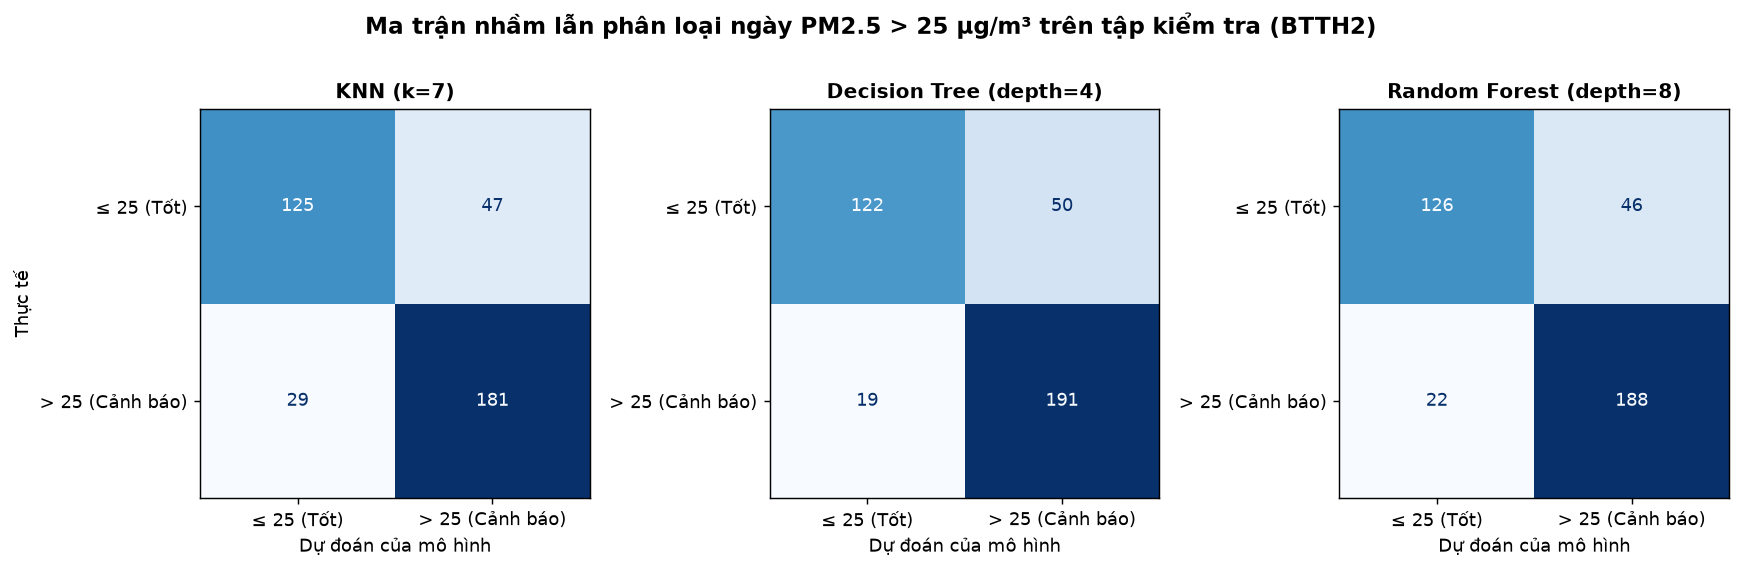

In [3]:
# Biểu đồ 1: Ma trận nhầm lẫn của 3 mô hình (cấu trúc y hệt ô 18 của BTTH2.ipynb)
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Segoe UI', 'Arial']
fig, axes = plt.subplots(ncols=3, figsize=(13.5, 4.2), dpi=130)
for i, (ten, m) in enumerate(models.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test_sc, y_test, ax=axes[i],
        display_labels=['≤ 25 (Tốt)', '> 25 (Cảnh báo)'],
        cmap='Blues', colorbar=False
    )
    axes[i].set_title(ten, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Dự đoán của mô hình')
    axes[i].set_ylabel('Thực tế' if i == 0 else '')
fig.suptitle('Ma trận nhầm lẫn phân loại ngày PM2.5 > 25 µg/m³ trên tập kiểm tra (BTTH2)', fontsize=12.5, fontweight='bold', y=1.02)
plt.tight_layout()

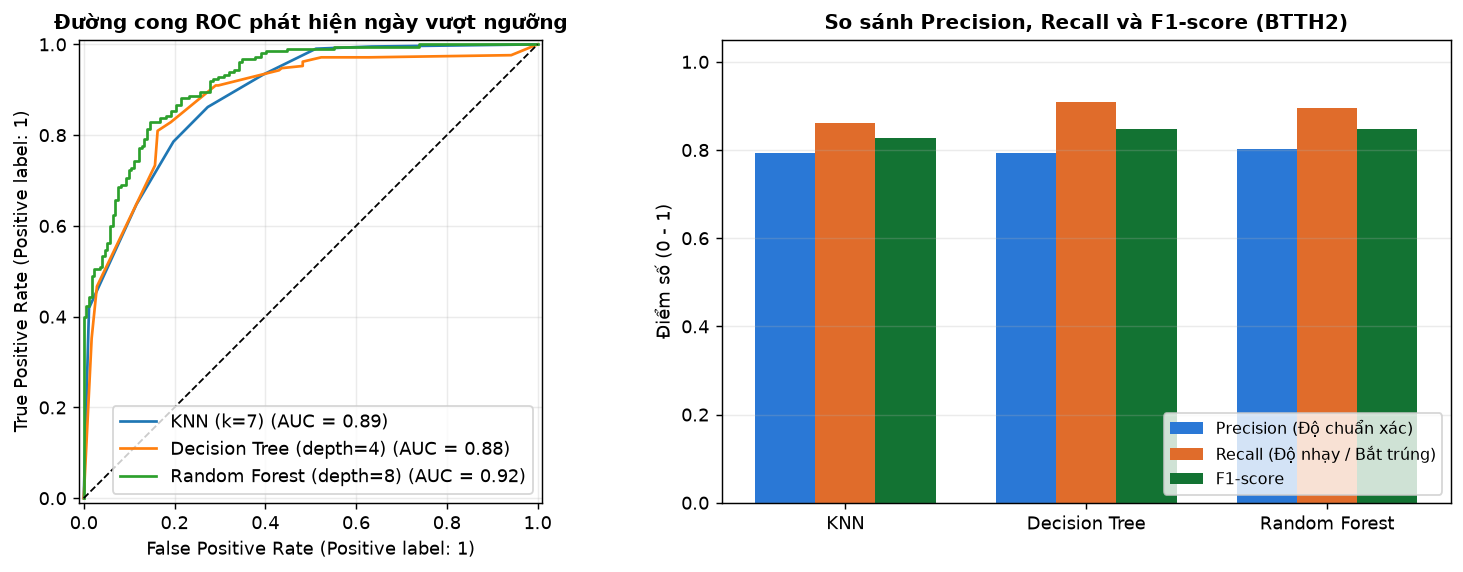

In [4]:
# Biểu đồ 2: Đường cong ROC & so sánh F1-score / Recall (cấu trúc ô 32 của BTTH2.ipynb)
fig, axes = plt.subplots(ncols=2, figsize=(12, 4.5), dpi=130)
for ten, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test_sc, y_test, ax=axes[0], name=ten)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Ngẫu nhiên (AUC = 0.50)')
axes[0].set_title('Đường cong ROC phát hiện ngày vượt ngưỡng', fontsize=11, fontweight='bold')
axes[0].grid(alpha=0.25)

x = np.arange(len(df_val))
w = 0.25
axes[1].bar(x - w, df_val['Precision'], width=w, label='Precision (Độ chuẩn xác)', color='#2a78d6')
axes[1].bar(x, df_val['Recall'], width=w, label='Recall (Độ nhạy / Bắt trúng)', color='#e06c2b')
axes[1].bar(x + w, df_val['F1'], width=w, label='F1-score', color='#137333')
axes[1].set_xticks(x)
axes[1].set_xticklabels([m.split(' (')[0] for m in df_val['model']])
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Điểm số (0 - 1)')
axes[1].set_title('So sánh Precision, Recall và F1-score (BTTH2)', fontsize=11, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(axis='y', alpha=0.25)
plt.tight_layout()